# Shot 50 Analysis

Decaying shock in fused silica near the temperature inversion on the principal Hugoniot.

Flyer and driver are copper 101.

Erik Davies<br>
Sarah T. Stewart<br>
July 26, 2024<br>
Updated May 13, 2025<br>


In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors


## Target Configuration

```{figure} ./shot50/shot50-target.png
---
width: 750px
name: shot50-target-info
---
```


## MAVIS Impact Velocity system

MAVIS inter-coil distance = 50.00 mm<br>
Time of Flight =  9.3406+/- 0.0056 us<br>
Velocity =  5.353 +/- 0.0039 km/s<br>

Anaysis file: MAVIS_Velocity_Analysis_v2.py


```{figure} ./shot50/Shot_50_MAVISRecord.png
---
width: 500px
name: shot50-mavis
---
```

## PDV Signals

3 channels; no signal in sample. <br>
PDV fibers and pyro fiber is touching free surface.<p>


```{figure} ./shot50/Shot_50_ProbeMap_Pre-Shot.png
---
width: 750px
name: shot50-Probe-map
---
```


## PDV Shock Velocities and Transit Thickness


Using Sandia SMASH-SIHREN2 v2.0 May 2023 to convert to shock front velocities.<br>

This looks like it might be the shock velocity in the fiber? It's not the sample.


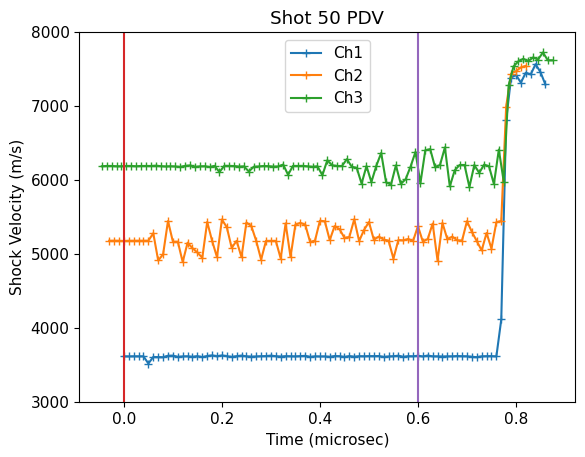

Text(0, 0.5, 'Shock Velocity (m/s)')

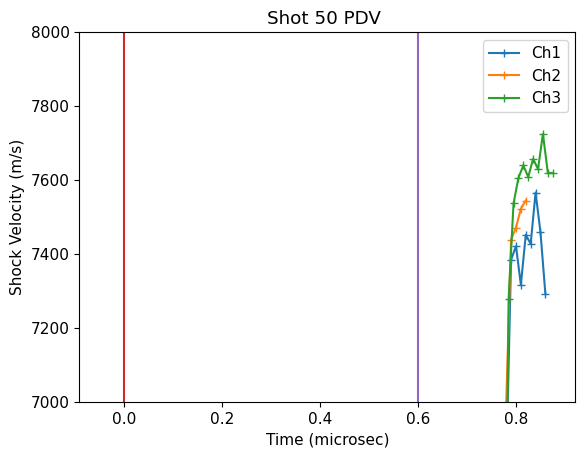

In [2]:

# Load SIHREN2 results - not corrected for offset or index

Ch1_offset = 2609 # m/s
pdv1data = np.loadtxt('shot50/Shot50-PDV-ch1.txt',skiprows=30)
pdv1data[:,0]-=pdv1data[0,0]
pdv1data[:,0]*=1.e6
#pdv1data[:,0]-=.06
pdv1data[:,1]+=Ch1_offset
pdv1data[:,1]/=1.444

Ch2_offset = 3736 # m/s
# n = 1.444
pdv2data = np.loadtxt('shot50/Shot50-PDV-ch2.txt',skiprows=30)
pdv2data[:,0]-=pdv2data[0,0]
pdv2data[:,0]*=1.e6
pdv2data[:,0]-=.03
pdv2data[:,1]+=Ch2_offset
pdv2data[:,1]/=1.444

Ch3_offset = 4468.8 # m/s
# n = 1.444
pdv3data = np.loadtxt('shot50/Shot50-PDV-ch3.txt',skiprows=30)
pdv3data[:,0]-=pdv3data[0,0]
pdv3data[:,0]*=1.e6
pdv3data[:,0]-=.045
pdv3data[:,1]+=Ch3_offset
pdv3data[:,1]/=1.444


plt.plot(pdv1data[:,0],pdv1data[:,1],'-+',label='Ch1')
plt.plot(pdv2data[:,0],pdv2data[:,1],'-+',label='Ch2')
plt.plot(pdv3data[:,0],pdv3data[:,1],'-+',label='Ch3')
plt.plot([0.,0.],[0,10000])
plt.plot([0.6,0.6],[0,10000])
plt.legend()
plt.ylim(3000,8000)

plt.title('Shot 50 PDV')
plt.xlabel('Time (microsec)')
plt.ylabel('Shock Velocity (m/s)')
plt.show()

plt.plot(pdv1data[:,0],pdv1data[:,1],'-+',label='Ch1')
plt.plot(pdv2data[:,0],pdv2data[:,1],'-+',label='Ch2')
plt.plot(pdv3data[:,0],pdv3data[:,1],'-+',label='Ch3')
plt.plot([0.,0.],[0,10000])
plt.plot([0.6,0.6],[0,10000])
plt.legend()
plt.ylim(7000,8000)

plt.title('Shot 50 PDV ')
plt.xlabel('Time (microsec)')
plt.ylabel('Shock Velocity (m/s)')

## Load Streak Temperature Data

See calibration and moving average notebook:

UCDavis_GasGunStreak_Direct_Cal_v2.ipynb

Using 20 ns moving average for temperature vs. time.

In [3]:
streak = np.loadtxt('shot50/S050_Lineout_timeprofile_620-660nm.txt',skiprows=2,delimiter=',')

calstreak = np.loadtxt('shot50/S050_TemperatureProfile_-1000-1000ns_20nsWindow.txt',skiprows=2,delimiter=',')

streak[:,0]+=-.035
calstreak[:,0]+=-.035


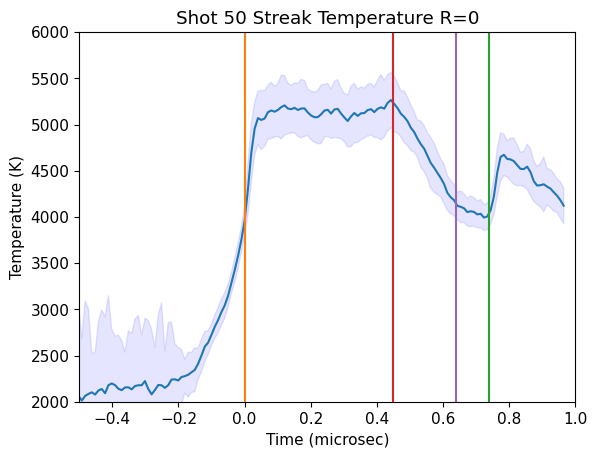

In [4]:
#plt.plot(streak[:,0],np.power(streak[:,1],.25)/1860*5100,label='scaled counts')
#plt.plot([-.2,1],[5100,5100])
#plt.plot([-.2,1],[3900,3900])
plt.xlim(-.5,1)

tdecay = 0.45
tend = 0.74
tkink = 0.64

plt.plot(calstreak[:,0],calstreak[:,1])
plt.fill_between(calstreak[:,0],calstreak[:,1]-calstreak[:,2],calstreak[:,1]+calstreak[:,2], color='blue', alpha = 0.1)
plt.plot([0.,0.],[0,6000])
plt.plot([tend,tend],[0,6000])
plt.plot([tdecay,tdecay],[0,6000])
plt.plot([tkink,tkink],[0,6000])
plt.title('Shot 50 Streak Temperature R=0')
plt.xlabel('Time (microsec)')
plt.ylabel('Temperature (K)')
plt.ylim(2000,6000)
plt.show()

The temperature profile shows a steady region, decay region and then nearly steady region again.
The nearly steady region is a wave interaction with the driver based on pyKO simulations.


## Construct Plausible Shock Velocity vs. Time


7619.740035122438
7619.740035122438 [   0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.
    0.            0

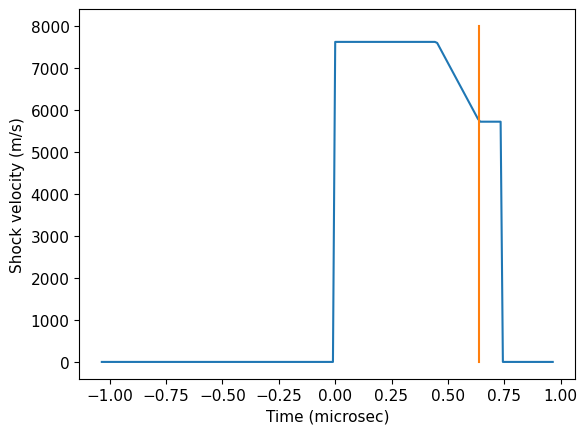

In [5]:
usstart=7620 # Based on impedance match solution

# pressure in IM solution 5/6/2025
usstart = np.interp(68.06,fs_hug_stv.P,fs_hug_stv.us)*1000 # m/s
print(usstart)

fittime = calstreak[:,0]
usfit = np.zeros(len(fittime))
ind = np.where((fittime>0) & (fittime<tdecay))[0]
usfit[ind]=usstart
ind = np.where((fittime>tdecay))[0]
usfit[ind]=(10000)*(tdecay-fittime[ind])+usstart
ind = np.where((fittime>tkink))[0]
usfit[ind]=np.interp(tkink,fittime,usfit)
ind = np.where((fittime>tend))[0]
usfit[ind]=0.

fitus2=np.copy(usfit)
plt.plot(fittime,fitus2)
#plt.plot([0.,0.],[0,8000])
#plt.plot([tend,tend],[0,8000])
#plt.plot(pdv1data[:,0],pdv1data[:,1],'-+',label='Ch1')
#plt.plot(pdv2data[:,0],pdv2data[:,1],'-+',label='Ch2')
#plt.plot(pdv3data[:,0],pdv3data[:,1],'-+',label='Ch3')
plt.xlabel('Time (microsec)')
plt.ylabel('Shock velocity (m/s)')
plt.plot([tkink,tkink],[0,8000])

# use the model for solid fs hugoniot region to extract corresponding P and up
pfit = np.interp(usfit/1.e3,fs_hug_stv.us,fs_hug_stv.P)
ind = np.where(calstreak[:,0]<0)[0]
pfit[ind]=0

upfit = np.interp(usfit/1.e3,fs_hug_stv.us,fs_hug_stv.up)
ind = np.where(calstreak[:,0]<0)[0]
upfit[ind]=0

print(usstart,usfit)
plt.show()

2.8703381912385595


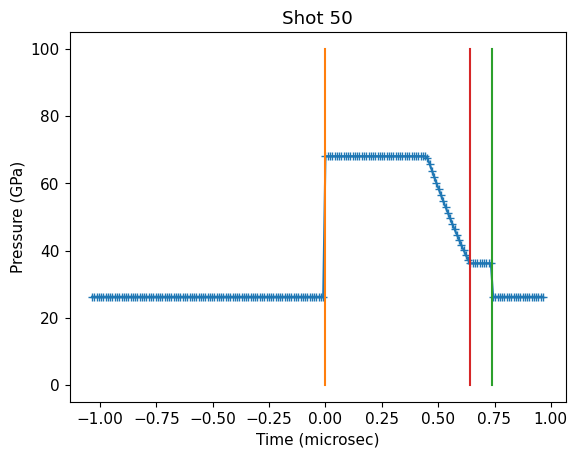

Pressure at the kink around (GPa) 36.50488380280096


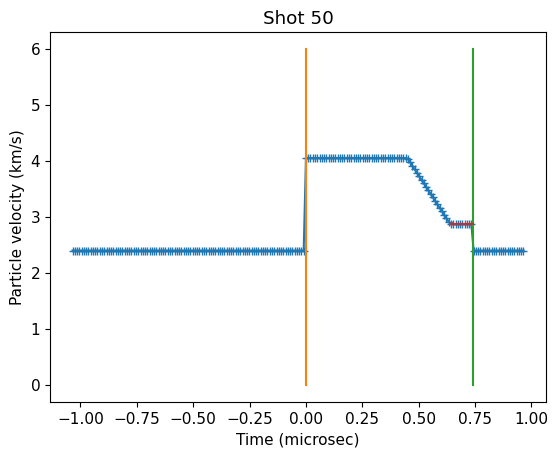

In [6]:
# convert Us to P using the liquid region fused silica fit
# latest version in scripts/define_eos.py
#fsresliq = [-0.01452743,  1.69390958,  1.15979627]
#fs_hug_liq.us = fsresliq[2]+fsresliq[1]*fs_hug_liq.up+fsresliq[0]*fs_hug_liq.up*fs_hug_liq.up # km/s
#fs_hug_liq.P = fs_hug_liq.rho_ref*fs_hug_liq.up*fs_hug_liq.us

fitpres2 = np.interp(usfit/1.e3,fs_hug_stv.us,fs_hug_stv.P)
fitup2 = np.interp(usfit/1.e3,fs_hug_stv.us,fs_hug_stv.up)
# fix the very first point at time zero
#ind0 = np.where(np.abs(pdv2data[:,0])<1.e-10)[0]
#print(ind0)
#pdv2data[ind0,0]=0.0
#fitpres2[ind0]=fitpres2[ind0+1]
#print(pdv2data[ind0+1,0]) #.01 microsec
# zero out earlier time pressures
ind = np.where(fitus2[:]<0)[0]
fitpres2[ind]=0
fitup2[ind]=0

#print(fitup2)
# print last particle velocity before breakout
ind = np.where(fittime<tend)[0]
print(fitup2[max(ind)])
lastup2 = fitup2[max(ind)]
lastp2 = fitpres2[max(ind)]

plt.plot(fittime,fitpres2,'-+')
plt.plot([0.,0.],[0,100])
plt.plot([tend,tend],[0,100])
plt.plot([tkink,tkink],[0,100])
plt.title('Shot 50')
plt.xlabel('Time (microsec)')
plt.ylabel('Pressure (GPa)')
plt.show()

print('Pressure at the kink around (GPa)',np.interp(tkink,fittime,fitpres2))

plt.plot(fittime,fitup2,'-+')
plt.plot([0.,0.],[0,6])
plt.plot([tend,tend],[0,6])
plt.plot([tkink,tend],[lastup2,lastup2])
plt.title('Shot 50')
plt.xlabel('Time (microsec)')
plt.ylabel('Particle velocity (km/s)')
plt.show()

In [7]:
# check thickness
xpos2 = [0.]
for i in range(1,len(calstreak[:,0])):
    dt = calstreak[i,0]-calstreak[i-1,0]
    x2=usfit[i]*dt+xpos2[i-1]
    xpos2.append(x2)

xpos2 = np.asarray(xpos2)


print('Shock travel distance for model shock vel profile in mm = ',max(xpos2/1.e3))

print('Actual target thickness in center = 5.297+-0.0015 mm')

Shock travel distance for model shock vel profile in mm =  5.2986107298913145
Actual target thickness in center = 5.297+-0.0015 mm


68.05999999999999 1.4210854715202004e-14
5170.920498064298 19.364571422900298
292.00997504453255


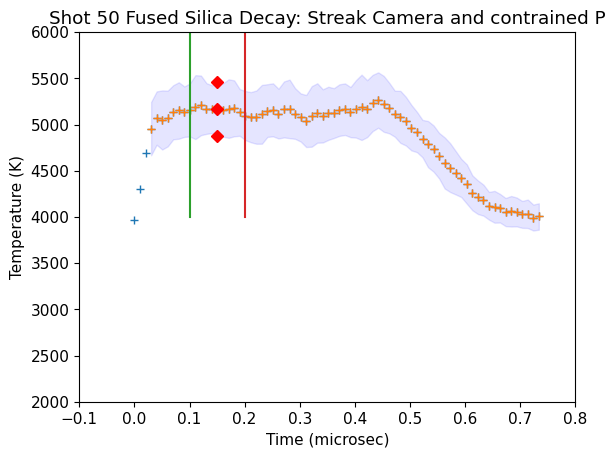

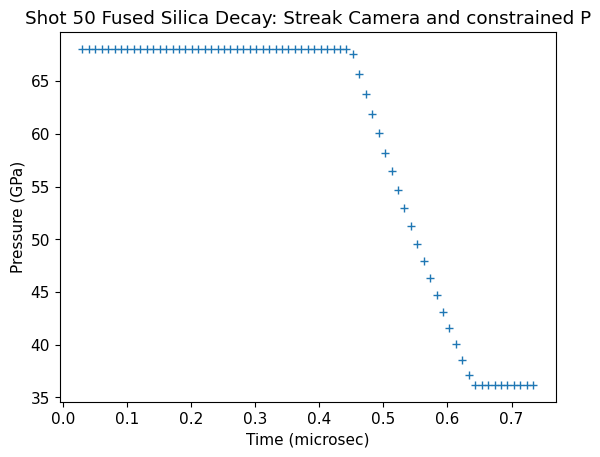

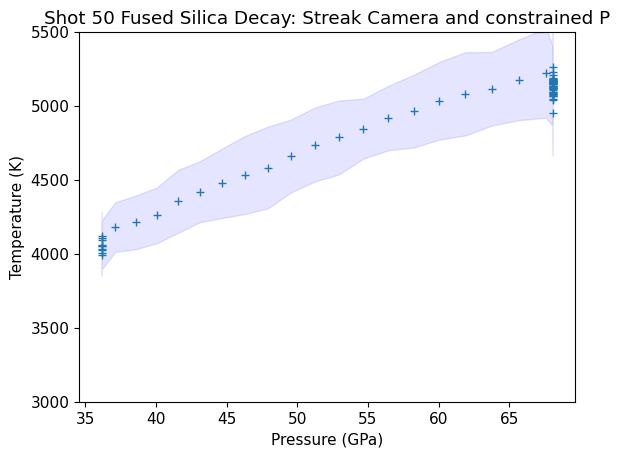

In [8]:

s50time = fittime
s50temp = np.copy(calstreak[:,1])
s50temperr = np.copy(calstreak[:,2])
s50pres = fitpres2
s50us = fitus2
s50up = fitup2

ind = np.where(s50time<0)[0]
s50temp[ind]=0.
s50pres[ind]=0.
#s50temp[max(ind):max(ind)+9]=0.
#s50pres[max(ind):max(ind)+9]=0.
ind = np.where(s50time>tend)[0]
s50temp[ind]=0.
s50pres[ind]=0.


# average top of the shock wave
t1=0.1 # microsec
t2=0.2
itop = np.where((s50time > t1) & (s50time < t2))[0]
print(np.mean(s50pres[itop]),np.std(s50pres[itop]))
print(np.mean(s50temp[itop]),np.std(s50temp[itop]))
Tsteady = np.mean(s50temp[itop])
Tsteady_err = np.mean(s50temperr[itop])
Psteady = np.mean(s50pres[itop])

# remove the time period where the temperature is still rising in the streak camera
ind50 = np.where((s50time > 0.025) & (s50time <tend))[0]

plt.plot(s50time,s50temp,'+')
plt.plot(s50time[ind50],s50temp[ind50],'+')
plt.fill_between(s50time[ind50],s50temp[ind50]-s50temperr[ind50],s50temp[ind50]+s50temperr[ind50], color='blue', alpha = 0.1)
plt.ylim(2000,6000)
plt.xlim(-.1,.8)
plt.plot([.1,.1],[4000,6500])
plt.plot([.2,.2],[4000,6500])
plt.xlabel('Time (microsec)')
plt.ylabel('Temperature (K)')
plt.title('Shot 50 Fused Silica Decay: Streak Camera and contrained P')

print(Tsteady_err)
#Tsteady_err=250
plt.plot([.15],[Tsteady],'rD')
plt.plot([.15],[Tsteady+Tsteady_err],'rD')
plt.plot([.15],[Tsteady-Tsteady_err],'rD')

plt.show()


plt.plot(s50time[ind50],s50pres[ind50],'+')
plt.ylabel('Pressure (GPa)')
plt.xlabel('Time (microsec)')
plt.title('Shot 50 Fused Silica Decay: Streak Camera and constrained P')

plt.show()


isort = np.argsort(s50pres[ind50])
#print(isort)
plt.plot(s50pres[ind50],s50temp[ind50],'+')
plt.fill_between(s50pres[ind50[isort]],s50temp[ind50[isort]]-s50temperr[ind50[isort]],s50temp[ind50[isort]]+s50temperr[ind50[isort]], color='blue', alpha = 0.1)
plt.ylim(3000,5500)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Shot 50 Fused Silica Decay: Streak Camera and constrained P')


plt.show()

In [9]:
# estimate expected temperature before breakout

lasttemp = np.interp(lastup2,fs_hug_stv.up,fs_hug_stv.T)
print(lastup2,lasttemp)
print(Tsteady,Tsteady_err)
print(Psteady)


2.8703381912385595 3350.4121176880917
5170.920498064298 292.00997504453255
68.05999999999999


## Plot with other fused silica data


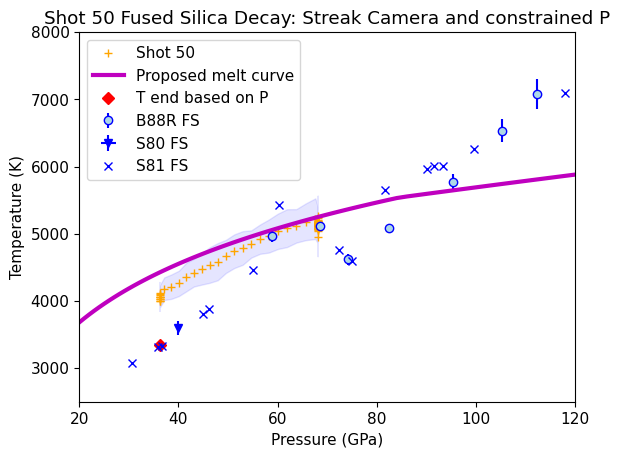

In [10]:

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Shot 50 Fused Silica Decay: Streak Camera and constrained P')
plt.plot(s50pres[ind50],s50temp[ind50],'+',color='orange',label='Shot 50')
plt.fill_between(s50pres[ind50[isort]],s50temp[ind50[isort]]-s50temperr[ind50[isort]],s50temp[ind50[isort]]+s50temperr[ind50[isort]], color='blue', alpha = 0.1)

if 1:
    #plt.errorbar(shockdat_list[B88fs['id']].P,shockdat_list[B88fs['id']].T,fmt='bo',mfc='white',yerr=shockdat_list[B88fs['id']].T_std,label=B88fs['lab'])
    ind = np.where(shockdat_list[B88RRfs['id']].T>0)
    plt.errorbar(shockdat_list[B88RRfs['id']].P[ind],shockdat_list[B88RRfs['id']].T[ind],fmt='bo',mfc='lightblue',yerr=shockdat_list[B88RRfs['id']].T_std[ind],label=B88RRfs['lab'])

    plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
    plt.errorbar(shockdat_list[S81fs['id']].P,shockdat_list[S81fs['id']].T,fmt='bx',label=S81fs['lab'])
    plt.xlim(20,120)
    plt.ylim(2500,8000)
    plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Proposed melt curve')

plt.plot([lastp2],[lasttemp],'rD',label='T end based on P')

plt.legend()
plt.savefig(outputfigpath+'shot50-comp-data.png')
plt.show()

## Compare to Omega Fused Silica decaying shock


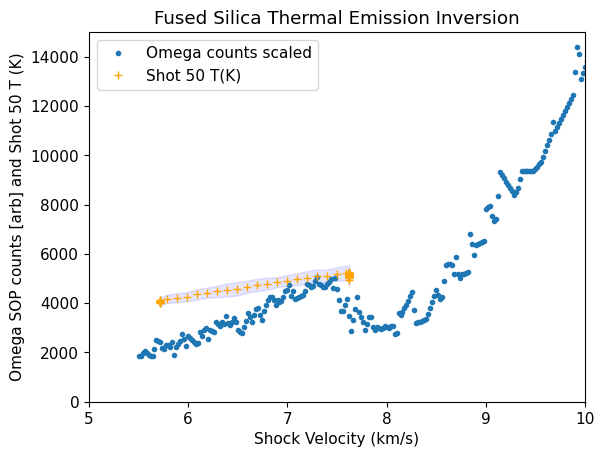

Transition pressures:  65.75879401343992 73.53695488293766


In [11]:
plt.plot(shockdat[iMDfs69691.i].us,shockdat[iMDfs69691.i].T*20,'.',label='Omega counts scaled')
plt.ylim(0,15000)
plt.xlim(5.,10)

plt.plot(s50us[ind50]/1.e3,s50temp[ind50],'+',color='orange',label='Shot 50 T(K)')
plt.fill_between(s50us[ind50[isort]]/1.e3,s50temp[ind50[isort]]-s50temperr[ind50[isort]],s50temp[ind50[isort]]+s50temperr[ind50[isort]], color='blue', alpha = 0.1)


plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Omega SOP counts [arb] and Shot 50 T (K)')
plt.title('Fused Silica Thermal Emission Inversion')
plt.legend()
plt.savefig(outputfigpath+'shot50-withomega.png')
plt.show()
#'rasterized=True' 
print('Transition pressures: ',fs_wiggle_P1, fs_wiggle_P2)

## PDV release velocity

No index correction for free surface particle velocity.

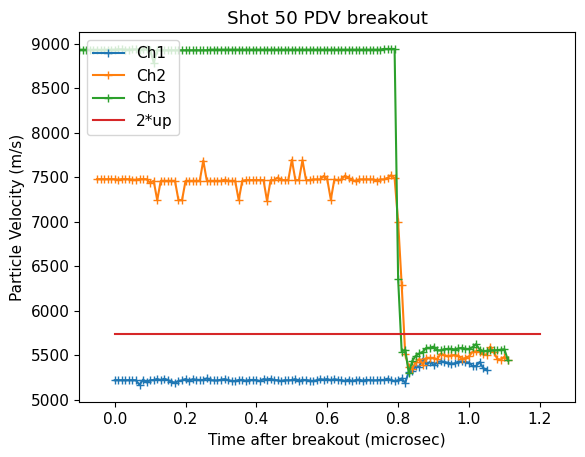

In [12]:
pdv1datab = np.loadtxt('shot50/Shot50-PDV-ch1-breakout.txt',skiprows=30)
pdv1datab[:,0]-=pdv1datab[0,0]
pdv1datab[:,0]*=1.e6
pdv1datab[:,1]+=Ch1_offset

pdv2datab = np.loadtxt('shot50/Shot50-PDV-ch2-breakout.txt',skiprows=30)
pdv2datab[:,0]-=pdv2datab[0,0]
pdv2datab[:,0]*=1.e6
pdv2datab[:,0]-=.05
pdv2datab[:,1]+=Ch2_offset

pdv3datab = np.loadtxt('shot50/Shot50-PDV-ch3-breakout.txt',skiprows=30)
pdv3datab[:,0]-=pdv3datab[0,0]
pdv3datab[:,0]*=1.e6
pdv3datab[:,0]-=.27
pdv3datab[:,1]+=Ch3_offset

plt.plot(pdv1datab[:,0],pdv1datab[:,1],'-+',label='Ch1')
plt.plot(pdv2datab[:,0],pdv2datab[:,1],'-+',label='Ch2')
plt.plot(pdv3datab[:,0],pdv3datab[:,1],'-+',label='Ch3')

plt.plot([0,1.2],[lastup2*2*1.e3,lastup2*2*1.e3],label='2*up')
plt.xlim(-.1,1.3)
plt.legend(loc='upper left')


plt.title('Shot 50 PDV breakout')
plt.xlabel('Time after breakout (microsec)')
plt.ylabel('Particle Velocity (m/s)')
plt.savefig(outputfigpath+'shot50-release-vel.png')
plt.show()

The release velocities are close to free surface doubling with the decay and plateau profile.

## NIR Pyro data

see Master_IR.ipynb

In [13]:
class IR:
    def __init__(self, temps, data):
        self.c1 = 1.19118*1.e-16
        self.c2 = 1.4388*1.e-2
        self.wvln_cal = 0.
        self.n = len(temps)
        self.T_cal = np.zeros(self.n)
        self.Tr_max = 0.
        self.T_max = 0.
        self.K = np.zeros(self.n)
        self.K_er = np.zeros(self.n)
        self.Sc = np.zeros(self.n)
        self.Sc_er = np.zeros(self.n)
        self.Kavg = 0.
        self.Kavg_er = 0.
        self.calctemp = 0.
        self.em = 0.
        self.em_er = 0.
        self.em_r = 0.
        self.em_r_er = 0.
        self.dark = 0
        self.dark_er = 0.
        self.ND = 0.
        self.L_cor = 0.
        self.L_cor_er = 0.
        self.abs_coeff = 0.
        self.abs_u = 0.
        self.T_high = 0.
        self.T_low = 0.
        self.L_new_high = 0.
        self.L_new_low = 0.
        self.abs_shock = 0.
        self.abs_shock_high = 0.
        self.abs_shock_low = 0.
        self.avg_release_L = 0.
        self.avg_release_Tr = 0.
        self.avg_release_T = 0.
        self.rel_percent_er = 0.
        self.Tr = np.zeros(len(data))
        self.Tr_er = np.zeros(len(data))
        self.T = np.zeros(len(data))
        self.T_er = np.zeros(len(data))
        self.L = np.zeros(len(data))
        self.L_er = np.zeros(len(data))
        self.L_rad = np.zeros(len(data))
        self.L_rad_er = np.zeros(len(data))
        self.L_plus = np.zeros(len(data))
        self.L_minus = np.zeros(len(data))
        self.L_rad_plus = np.zeros(len(data))
        self.L_rad_minus = np.zeros(len(data))
        self.shot_V = []
        self.shot_t = []
        self.L_fit_error = 0.
        self.rel_L_er = 0.
        self.ni = 0.

    def calibrate(self, wavelength, temperature, Sc, Sc_er):
        self.wvln_cal = wavelength * 1.e-6
        for i in range(self.n):
            self.T_cal[i] = temperature[i] + 273.
        self.Sc = Sc
        self.Sc_er = Sc_er
        for i in range(self.n):
            self.K[i] = self.Sc[i]*(np.exp(self.c2/(self.wvln_cal*self.T_cal[i]))-1)
        for i in range(self.n):
            self.K_er[i] = np.sqrt(((((np.exp(self.c2/(self.wvln_cal*self.T_cal[i])))-1)**2)*((self.Sc_er[i])**2))+(((-self.Sc[i]*(self.c2/(self.wvln_cal*(self.T_cal[i])**2))*np.exp(self.c2/(self.wvln_cal*self.T_cal[i])))**2)*(self.T_cal[i]*0.02)**2))
        self.Kavg = np.average(self.K, weights=(1/(self.K_er**2)))
        self.Kavg_er = 1/(np.sum((1/((self.K_er)**2))))

    def calcT(self, data_V, data_t, wavelength, ND, emissivity, emissivity_error):
        FR=abs((self.ni - 1) / (self.ni + 1))**2
        self.wvln = wavelength *1.e-6
        self.em = emissivity
        self.em_er = emissivity_error
        self.ND = ND
        self.data_V = data_V
        self.shot_t = data_t
        findDark(self)
        self.shot_V = (self.dark-self.data_V)*self.ND
        self.Tr_max = self.c2/(self.wvln_cal*np.log(self.Kavg/5 +1))
        self.T_max = self.c2/(self.wvln*np.log(self.em*np.exp(self.c2/(self.wvln*self.Tr_max))+1))
        for i in range(len(self.shot_V)):
            if (self.shot_V[i]>0):
                self.Tr[i] = self.c2/(self.wvln*np.log(self.Kavg/self.shot_V[i] +1))
                self.Tr_er[i] = np.sqrt(((((-self.c2)/(self.wvln*(self.Kavg+self.shot_V[i])*((np.log((self.Kavg/self.shot_V[i])+1))**2)))**2)*(self.Kavg_er**2))+((((self.c2*self.Kavg)/(self.wvln*((np.log((self.Kavg/self.shot_V[i])+1))**2)*self.shot_V[i]*(self.shot_V[i]+self.Kavg)))**2)*(0.001**2)))
            else:
                self.Tr[i] = self.c2/(self.wvln*np.log(self.Kavg/0.000001 +1))
                self.Tr_er[i] = np.sqrt((((-self.c2/self.wvln)*(1/(self.Kavg*(np.log(self.Kavg/0.00001))**2)))**2)*(self.Kavg_er**2)+(((self.c2/self.wvln)*(1/(0.00001*(np.log(self.Kavg/0.00001))**2)))**2)*(0.0001**2))
        for i in range(len(self.shot_V)):
            self.T[i] = self.c2/(self.wvln*(np.log(self.em*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)+1)))
            self.L[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*self.T[i]))-1)) * (1+FR)
            self.T_er[i] = np.sqrt((((((self.c2**2)*self.em*np.exp(self.c2/(self.wvln*self.Tr[i])))/((self.wvln**2)*(self.Tr[i]**2)*(self.em*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)+1)*(((np.log(self.em*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)))**2) +1)))**2)*(self.Tr_er[i]**2)) + (((-1*self.c2*(np.exp((self.c2/(self.wvln*self.Tr[i])))-1))/(self.wvln*((np.exp((self.c2/(self.wvln*self.Tr[i])))-1)*self.em+1)*np.log((np.exp((self.c2/(self.wvln*self.Tr[i])))-1)*self.em+1)**2))**2)*(self.em_er**2))
            self.L_plus[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*(self.T[i]+self.T_er[i])))-1)) * (1+FR)
            self.L_minus[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*(self.T[i]-self.T_er[i])))-1)) * (1+FR)
            #self.L_er[i] = np.sqrt((((((self.c2**2)*(self.wvln**4)*np.exp(self.c2/(self.wvln*self.T[i])))/((self.T[i]**2)*((self.wvln**5)*np.exp(self.c2/(self.wvln*self.T[i]))-1)**2))**2)*(self.T_er[i])**2))
            self.L_er[i] = np.sqrt((((self.c1*self.c2*np.exp(self.c2/(self.wvln*self.T[i])))/(self.wvln**6*self.T[i]*(np.exp(self.c2/(self.wvln*self.T[i]))-1)**2))*(self.T_er[i])**2))

        for i in range(len(self.shot_V)):
            self.L_rad[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)) * (1+FR)
            self.L_rad_er[i] = np.sqrt((((self.c1*self.c2*np.exp(self.c2/(self.wvln*self.Tr[i])))/(self.wvln**6*self.Tr[i]*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)**2))*(self.Tr_er[i])**2))
            #self.L_rad_er[i] = np.sqrt((((((self.c2**2)*(self.wvln**4)*np.exp(self.c2/(self.wvln*self.Tr[i])))/((self.Tr[i]**2)*((self.wvln**5)*np.exp(self.c2/(self.wvln*self.Tr[i]))-1)**2))**2)*(self.Tr_er[i])**2))
            #self.L_rad_plus[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*(self.Tr[i]+self.Tr_er[i])))-1))
            #self.L_rad_minus[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*(self.Tr[i]-self.Tr_er[i])))-1))
            self.L_rad_plus[i] = self.L_rad[i] + self.L_rad_er[i]
            self.L_rad_minus[i] = self.L_rad[i] - self.L_rad_er[i]
            
            
    def calcTrueT(self,fitL):
        Tr_fit = solveT(self,fitL)
        self.T = self.c2/(self.wvln*(np.log(self.em*(np.exp(self.c2/(self.wvln*Tr_fit))-1)+1)))
        self.L_cor = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*self.T))-1))
        self.L_cor_er = np.sqrt((((((self.c2**2)*(self.wvln**4)*np.exp(self.c2/(self.wvln*self.T)))/((self.T**2)*((self.wvln**5)*np.exp(self.c2/(self.wvln*self.T))-1)**2))**2)*(self.T_er)**2)-((self.c2*(np.exp((self.c2/(self.wvln*self.T)))-1))/(self.wvln*((np.exp((self.c2/(self.wvln*self.T)))-1)*self.em+1)*np.log((np.exp((self.c2/(self.wvln*self.T)))-1)*self.em+1)**2))*(self.em_er**2))
    def collect(self,abs_coeff,Ter_high, Ter_low, L_high, L_low, absshock, shockhigh, shocklow):
        self.abs_coeff = abs_coeff
        self.T_high = Ter_high
        self.T_low = Ter_low
        self.L_new_high = L_high
        self.L_new_low = L_low
        self.abs_shock = absshock
        self.abs_shock_high = shockhigh
        self.abs_shock_low = shocklow
    
    def calcT_OLD(self, data_V, data_t, dark, wavelength, ND, emissivity):
        self.wvln = wavelength *1.e-6
        self.em = emissivity
        self.ND = ND
        self.dark = dark
        self.data_V = data_V
        self.shot_V = (self.dark-self.data_V)*self.ND
        self.shot_t = data_t
        self.Tr_max = self.c2/(self.wvln_cal*np.log(self.Kavg/5 +1))
        self.T_max = self.c2/(self.wvln*np.log(self.em*np.exp(self.c2/(self.wvln*self.Tr_max))+1))
        for i in range(len(self.shot_V)):
            if (self.shot_V[i]>0):
                self.Tr[i] = self.c2/(self.wvln*np.log(self.Kavg/self.shot_V[i] +1))
                self.Tr_er[i] = np.sqrt(((((-self.c2)/(self.wvln*(self.Kavg+self.shot_V[i])*((np.log((self.Kavg/self.shot_V[i])+1))**2)))**2)*(self.Kavg_er**2))+((((self.c2*self.Kavg)/(self.wvln*((np.log((self.Kavg/self.shot_V[i])+1))**2)*self.shot_V[i]*(self.shot_V[i]+self.Kavg)))**2)*(0.001**2)))
            else:
                self.Tr[i] = self.c2/(self.wvln*np.log(self.Kavg/0.000001 +1))
                self.Tr_er[i] = np.sqrt((((-self.c2/self.wvln)*(1/(self.Kavg*(np.log(self.Kavg/0.00001))**2)))**2)*(self.Kavg_er**2)+(((self.c2/self.wvln)*(1/(0.00001*(np.log(self.Kavg/0.00001))**2)))**2)*(0.0001**2))
        for i in range(len(self.shot_V)):
            self.T[i] = self.c2/(self.wvln*(np.log(self.em*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)+1)))
            self.L[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*self.T[i]))-1))
            self.T_er[i] = np.sqrt(((((self.c2**2)*self.em*np.exp(self.c2/(self.wvln*self.Tr[i])))/((self.wvln**2)*(self.Tr[i]**2)*(self.em*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)+1)*(((np.log(self.em*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)))**2) +1)))**2)*(self.Tr_er[i]**2))
            self.L_er[i] = np.sqrt((((((self.c2**2)*(self.wvln**4)*np.exp(self.c2/(self.wvln*self.T[i])))/((self.T[i]**2)*((self.wvln**5)*np.exp(self.c2/(self.wvln*self.T[i]))-1)**2))**2)*(self.T_er[i])**2))

    def fitShock(self, print_result, toffset, start, us, samplethick, sampleT):
        self.shift_time = np.zeros(len(self.shot_t))
        R1 = 0. #driver-sample
        R2 = 0. #shock front
        R3 = findR(self.ni)
        for i in range(len(self.shot_t)):
            self.shift_time[i] = self.shot_t[i]+toffset/1.e6
        
        find_ind = np.where((self.shift_time > start/1.e6) & (self.shift_time < (samplethick/us)))
        ind=len(find_ind[0])

        self.new_time = np.zeros(ind)
        self.new_L = np.zeros(ind)
        self.L_high = np.zeros(ind)
        self.L_low = np.zeros(ind)
        
        if print_result == 1:
            print('transit time = ',(samplethick/us)*1.e9)
        transittime = samplethick/us

        j=0
        for i in range(len(self.shift_time)):
            if ((start*1.e-6 < self.shift_time[i]) and (self.shift_time[i] < transittime)):
                self.new_time[j] = self.shift_time[i]
                self.new_L[j] = self.L[i]
                self.L_high[j] = self.L_plus[i]
                self.L_low[j] = self.L_minus[i]
                j+=1
                
        self.fit_a_only = np.zeros(len(self.new_time))
        self.no_param_fit = np.zeros(len(self.new_time))
        self.fit_a_L = np.zeros(len(self.new_time))
        self.fit_L_high = np.zeros(len(self.new_time))
        self.fit_L_low = np.zeros(len(self.new_time))

        #functions used into below curve_fit. 
        #Variable a is the shocked abs and b is the luminosity of the sample.
        func_1 = lambda x,a: (1-R2)*(1-R3)*findL(sampleT,self.wvln)*(1-np.exp(-a*(us*x)))*np.exp(-self.abs_u*((samplethick-(us*x))))
        func_2 = lambda x,a,b: (1-R2)*(1-R3)*b*(1-np.exp(-a*(us*x)))*np.exp(-self.abs_u*((samplethick-(us*x))))
        func_3 = lambda x,a,b: (1-R2)*(1-R3)*b*(1-np.exp(-a*(us*x)))*np.exp(-(self.abs_u+(0.2*self.abs_u))*((samplethick-(us*x))))
        func_4 = lambda x,a,b: (1-R2)*(1-R3)*b*(1-np.exp(-a*(us*x)))*np.exp(-(self.abs_u-(0.2*self.abs_u))*((samplethick-(us*x))))

        
        Lguess=findL(sampleT,self.wvln)
        aguess=1000.
        fita,fitb = optimize.curve_fit(func_1, self.new_time, self.new_L, p0=[aguess]) #fitting a 
        fitc,fitd = optimize.curve_fit(func_2, self.new_time, self.new_L, p0=[aguess,Lguess]) #fitting a,L
        self.fit_high,self.fit_high_er = optimize.curve_fit(func_2, self.new_time, self.L_high, p0=[aguess,Lguess])
        self.fit_low,self.fit_low_er = optimize.curve_fit(func_2, self.new_time, self.L_low, p0=[aguess,Lguess])
    
        if print_result == 1:
            print('fitting for shock abs coeff in m^-1. First is best fit output second is estimated covariance of the fit.\n')
            print('for IR channel',self.wvln)
            print('abs_shock only',fita,fitb)
            print('abs_shock and L',fitc,fitd)
            print('temperature',findT(fitc[1],self.wvln))
            print('high',self.fit_high,self.fit_high_er)
            print('low',self.fit_low,self.fit_low_er)
    
        self.fit_abs_s = fitc[0]
        self.fit_L = fitc[1]
        
        self.fit_abs_s_high = self.fit_high[0]
        self.fit_abs_s_low = self.fit_low[0]
        self.fit_rad_high = self.fit_high[1]
        self.fit_rad_low = self.fit_low[1]

        self.plot_time = np.linspace(0,transittime,len(self.new_time))

        #using coefficient fits from above:
        for i in range(len(self.plot_time)):
            self.fit_a_only[i] = (1-R2)*(1-R3)*findL(sampleT,self.wvln)*(1-np.exp(-fita*(us*self.plot_time[i])))*np.exp(-self.abs_u*((samplethick-(us*self.plot_time[i]))))
            self.no_param_fit[i] = (1-R2)*(1-R3)*findL(sampleT,self.wvln)*(1.)*np.exp(-self.abs_u*((samplethick-(us*self.plot_time[i]))))
            self.fit_a_L[i] = (1-R2)*(1-R3)*self.fit_L*(1-np.exp(-self.fit_abs_s*(us*self.plot_time[i])))*np.exp(-self.abs_u*((samplethick-(us*self.plot_time[i]))))
            self.fit_L_high[i] = (1-R2)*(1-R3)*self.fit_high[1]*(1-np.exp(-self.fit_high[0]*(us*self.plot_time[i])))*np.exp(-self.abs_u*((samplethick-(us*self.plot_time[i]))))
            self.fit_L_low[i] = (1-R2)*(1-R3)*self.fit_low[1]*(1-np.exp(-self.fit_low[0]*(us*self.plot_time[i])))*np.exp(-self.abs_u*((samplethick-(us*self.plot_time[i]))))

        self.L_fit_error = ((self.fit_L-self.fit_low[1])+(self.fit_high[1]-self.fit_L))/2
            
    def fitRelease(self, print_results, rel_window_start, rel_window_end, em, emr):
        self.em_r = em
        self.em_r_er = emr
        print(self.em_r, self.em_r_er)
        find_ind = np.where(((rel_window_start*1.e-6 < self.shift_time) & (self.shift_time < rel_window_end*1.e-6)))
        ind=len(find_ind[0])
        
        temp_T = np.zeros(len(self.T))
        temp_L = np.zeros(len(self.T))
        temp_T_er = np.zeros(len(self.T))
        temp_L_plus = np.zeros(len(self.T))
        temp_L_minus = np.zeros(len(self.T))
        temp_L_er = np.zeros(len(self.T))

        
        for i in range(len(self.shot_V)):
            temp_T[i] = self.c2/(self.wvln*(np.log(self.em_r*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)+1)))
            temp_L[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*temp_T[i]))-1))
            temp_T_er[i] = np.sqrt((((((self.c2**2)*self.em_r*np.exp(self.c2/(self.wvln*self.Tr[i])))/((self.wvln**2)*(self.Tr[i]**2)*(self.em_r*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)+1)*(((np.log(self.em_r*(np.exp(self.c2/(self.wvln*self.Tr[i]))-1)))**2) +1)))**2)*(self.Tr_er[i]**2)) + (((-1*self.c2*(np.exp((self.c2/(self.wvln*self.Tr[i])))-1))/(self.wvln*((np.exp((self.c2/(self.wvln*self.Tr[i])))-1)*self.em_r+1)*np.log((np.exp((self.c2/(self.wvln*self.Tr[i])))-1)*self.em_r+1)**2))**2)*(self.em_r_er**2))
            temp_L[i] = self.c1/((self.wvln**5)*(np.exp(self.c2/(self.wvln*temp_T[i]))-1))
            temp_L_er[i] = np.sqrt((((self.c1*self.c2*np.exp(self.c2/(self.wvln*temp_T[i])))/(self.wvln**6*temp_T[i]*(np.exp(self.c2/(self.wvln*temp_T[i]))-1)**2))*(temp_T_er[i])**2))
        
        print(temp_T_er)
            
        
        self.temp_rel_L = np.zeros(ind)
        self.temp_rel_time = np.zeros(ind)
        self.temp_rel_L_er = np.zeros(ind)
        self.temp_rel_T = np.zeros(ind)
        self.temp_rel_T_er = np.zeros(ind)
        

        j=0
        for i in range(len(self.shift_time)):
            if ((rel_window_start*1.e-6 < self.shift_time[i]) & (self.shift_time[i] < rel_window_end*1.e-6)):
                self.temp_rel_time[j] = self.shift_time[i]
                self.temp_rel_L[j] = temp_L[i]
                self.temp_rel_L_er[j] = temp_L_er[i]
                self.temp_rel_T[j] = temp_T[i]
                self.temp_rel_T_er[j] = temp_T_er[i]
                j+=1
        
    
        self.avg_release_L = np.mean(self.temp_rel_L)
        self.avg_release_T = np.mean(self.temp_rel_T)
        #calcTrueT_rel(self,self.avg_release_Tr)
        self.rel_L_er = np.std(self.temp_rel_L)
        self.rel_T_er = np.average(self.temp_rel_T_er)
        #self.rel_percent_er = self.rel_L_er/self.avg_release_L

        if print_results == 1:
            print('Ch.',self.wvln,':\nL = ',self.avg_release_L/1.e9,' (W/sr/m2/nm)\nrad T = ',self.avg_release_Tr,' K\nT = ',self.avg_release_T,' K\n')  

          
def solveT(self,L):
    return ((1.4388*1.e-2)/self.wvln)*(1/np.log((1.19118*1.e-16)/(L*self.wvln**5)+1)) #K
def calcTrueT_rel(self,rel_Tr):
    self.avg_release_T = self.c2/(self.wvln*(np.log(self.em_r*(np.exp(self.c2/(self.wvln*rel_Tr))-1)+1)))
def findL(T,wvln):
    return (1.19118*1.e-16)/((wvln**5)*(np.exp((1.4388*1.e-2)/(wvln*T))-1)) # W/sr/m3
def findR(n):
    return ((n-1)/(n+1))**2
def findT(L,wvln):
    return ((1.4388*1.e-2)/wvln)*(1/np.log((1.19118*1.e-16)/(L*wvln**5)+1)) #K
def findDark(self):
    find_dark = np.where((self.shot_t > -1*1.e-6) & (self.shot_t < -0.3*1.e-6))
    temp_array = find_dark[0]
    dark_array = np.zeros(len(temp_array))
    j = temp_array[0]
    i = 0
    while j <= temp_array[-1]:
        dark_array[i] = self.data_V[j]
        j += 1
        i += 1
    self.dark = np.average(dark_array)
    self.dark_er = np.std(dark_array)
def absCoeff(filename, mat):
    abs_u_1 = np.loadtxt(filename, delimiter=' ', usecols=[0])
    abs_u_2 = np.loadtxt(filename, delimiter=' ', usecols=[1])
    abs_u_3 = np.loadtxt(filename, delimiter=' ', usecols=[2])
    abs_u_4 = np.loadtxt(filename, delimiter=' ', usecols=[3])
    
    ID = 10
    
    if mat == 'quartz1':
        ID = 0
        C1.ni = 1.5241
        C2.ni = 1.5156
        C3.ni = 1.4059 #using FS
        C4.ni = 1.3522 #using FS
    elif mat == 'quartz2':
        ID = 1
        C1.ni = 1.5241
        C2.ni = 1.5156
        C3.ni = 1.4059 #using FS
        C4.ni = 1.3522 #using FS
    elif mat == 'fusedsilica':
        ID = 2
    else:
        print('Issue with material ID')
        
    #loading absorption coefficients found in the lab
    abs_u_ch1 = abs_u_1[ID]
    abs_u_ch2 = abs_u_2[ID]
    abs_u_ch3 = abs_u_3[ID]
    abs_u_ch4 = abs_u_4[ID]

    #converting from /mm to /m to match below units
    C4.abs_u = abs_u_ch4*1.e3
    #C3.abs_u = abs_u_ch3*1.e3
    C3.abs_u = 50
    C2.abs_u = abs_u_ch2*1.e3
    C1.abs_u = abs_u_ch1*1.e3

    print('Absorption coefs for ',mat,' at 4.8, 3.5, 2.3, 1.8 micron channels [1/m]=', C4.abs_u, C3.abs_u, C2.abs_u, C1.abs_u)
            
            
class Vis():
    def __init__(self, data):
        self.c1 = 3.7417*1.e-16
        self.c2 = 2.22*1.e-2
        self.wvln_cal = 0
        self.T_cal = 0
        self.Tr_max = 0.
        self.T_max = 0.
        self.Sc = 0
        self.K = 0
        self.wvln = 0
        self.em = 0
        self.shot_V = []
        self.shot_t = []
        self.Tr = np.zeros(len(data))
        self.T = np.zeros(len(data))
        self.L = np.zeros(len(data))

    def calibrate(self, wavelength, temperature, Sc, dark, std_luminosity):
        self.wvln_cal = wavelength * 1.e-6
        self.T_cal = temperature
        self.std_lumi = std_luminosity
        self.Sc = Sc-dark
        self.K = self.std_lumi/self.Sc
#        self.K = self.Sc*(np.exp(self.c2/(self.wvln_cal*self.T_cal))-1)

    def calcT(self, data_V, data_t, dark, wavelength, emissivity, ND):
        self.wvln = wavelength *1.e-6
        self.em = emissivity
        self.ND = ND
        self.dark = dark
        self.data_V = data_V
        self.shot_V = (self.data_V-self.dark)*self.ND
        self.shot_t = data_t

In [14]:
import pickle
## compare streak and NIR channels

with open('./shot50/ir-objs.pkl','rb') as f:  # Python 3: open(..., 'rb')
    C1,C2,C3,C4= pickle.load(f)

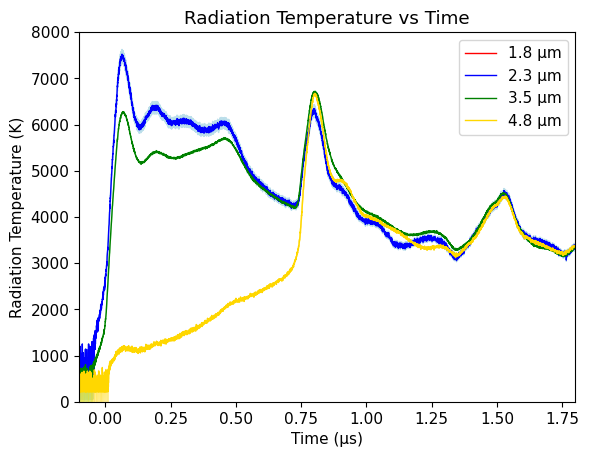

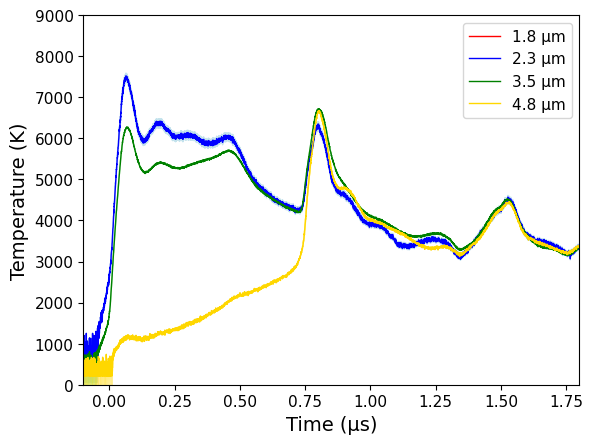

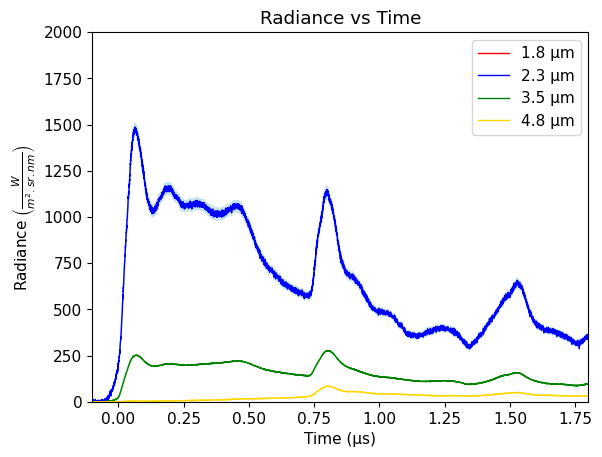

In [15]:
#All plot file names to update:
outdir='./shot50/'
Rad_T_file = outdir+'s50_RadT'
True_T_file = outdir+'s50_TrueT'
Rad_file = outdir+'s50_Rad'
#Ch4_shock_fit_file = outdir+'s50_ch4_fit'
#Ch3_shock_fit_file = outdir+'s50_ch3_fit'
#Ch2_shock_fit_file = outdir+'s50_ch2_fit'
#Ch1_shock_fit_file = outdir+'s50_ch1_fit'
#Planck_shock = outdir+'s50_apparent_Planck_fit.png'
#Planck_release = outdir+'s50_release_Planck.png'
output_file = outdir+'output.txt'

#Plots
#Radiation Tempearture vs time
plt.figure()
plt.plot(C1.shot_t*1.e6, C1.Tr, label='1.8 μm', linewidth=1,color='red')
plt.fill_between(C1.shot_t*1.e6, C1.Tr-C1.Tr_er, C1.Tr+C1.Tr_er, alpha=0.3, color='pink')
plt.plot(C2.shot_t*1.e6, C2.Tr, label='2.3 μm', linewidth=1,color='blue')
plt.fill_between(C2.shot_t*1.e6, C2.Tr-C2.Tr_er, C2.Tr+C2.Tr_er, alpha=0.8, color='lightblue')
plt.plot(C3.shot_t*1.e6, C3.Tr, label='3.5 μm', linewidth=1,color='green')
plt.fill_between(C3.shot_t*1.e6, C3.Tr-C3.Tr_er, C3.Tr+C3.Tr_er, alpha=0.4, color='lightgreen')
plt.plot(C4.shot_t*1.e6, C4.Tr, label='4.8 μm', linewidth=1,color='gold')
plt.fill_between(C4.shot_t*1.e6, C4.Tr-C4.Tr_er, C4.Tr+C4.Tr_er, alpha=0.4, color='gold')
#plt.plot(V1.shot_t*1.e6, V1.T, label='V1', linewidth=1)
#plt.plot(V2_data_t*1.e6, V2.T, label='V2', linewidth=1)
plt.xlabel('Time (μs)')
plt.ylabel('Radiation Temperature (K)')
plt.title('Radiation Temperature vs Time')
plt.xlim(-0.1, 1.8)
plt.ylim(0,8000)
#plt.grid()
plt.legend(loc='upper right')
#plt.savefig(Rad_T_file, format='pdf', dpi=1047,transparent=True) #high quality pdf save
plt.savefig(Rad_T_file + '.pdf', format='pdf', transparent=True)
plt.savefig(Rad_T_file + '.png',format='png', dpi=200,transparent=False)

#True temperature vs time
plt.figure()
plt.plot(C1.shot_t*1.e6, C1.T, label='1.8 μm', linewidth=1,color='red')
plt.fill_between(C1.shot_t*1.e6, C1.T-C1.T_er, C1.T+C1.T_er, alpha=0.3, color='pink')
plt.plot(C2.shot_t*1.e6, C2.T, label='2.3 μm', linewidth=1,color='blue')
plt.fill_between(C2.shot_t*1.e6, C2.T-C2.T_er, C2.T+C2.T_er, alpha=0.7, color='lightblue')
plt.plot(C3.shot_t*1.e6, C3.T, label='3.5 μm', linewidth=1,color='green')
plt.fill_between(C3.shot_t*1.e6, C3.T-C3.T_er, C3.T+C3.T_er, alpha=0.4, color='lightgreen')
plt.plot(C4.shot_t*1.e6, C4.T, label='4.8 μm', linewidth=1,color='gold')
plt.fill_between(C4.shot_t*1.e6, C4.T-C4.T_er, C4.T+C4.T_er, alpha=0.4, color='gold')
#plt.plot(V1.shot_t*1.e6, V1.T, label='V1', linewidth=1)
#plt.plot(V2_data_t*1.e6, V2.T, label='V2', linewidth=1)
plt.xlabel('Time (μs)', fontsize=14)
plt.ylabel('Temperature (K)', fontsize=14)
#plt.title('True Temperature vs Time')
plt.xlim(-0.1, 1.8)
plt.ylim(0,9000)
#plt.grid()
plt.legend(loc='upper right')
##plt.savefig(True_T_file, format='pdf', dpi=1047,transparent=True) #high quality pdf save
plt.savefig(True_T_file + '.pdf', format='pdf',transparent=True)
plt.savefig(True_T_file + '.png',format='png', dpi=200,transparent=False)

#Radiance vs time
plt.figure()
plt.plot(C1.shot_t*1.e6, C1.L/1.e9, label='1.8 μm', linewidth=1,color='red')
plt.fill_between(C1.shot_t*1.e6, C1.L_plus/1.e9, C1.L_minus/1.e9, alpha=0.3, color='pink')
plt.plot(C2.shot_t*1.e6, C2.L/1.e9, label='2.3 μm', linewidth=1,color='blue')
plt.fill_between(C2.shot_t*1.e6, C2.L_plus/1.e9, C2.L_minus/1.e9, alpha=0.7, color='lightblue')
plt.plot(C3.shot_t*1.e6, C3.L/1.e9, label='3.5 μm', linewidth=1,color='green')
plt.fill_between(C3.shot_t*1.e6, C3.L_plus/1.e9, C3.L_minus/1.e9, alpha=0.7, color='lightgreen')
plt.plot(C4.shot_t*1.e6, C4.L/1.e9, label='4.8 μm', linewidth=1,color='gold')
plt.fill_between(C4.shot_t*1.e6, C4.L_plus/1.e9, C4.L_minus/1.e9, alpha=0.4, color='gold')
plt.xlabel('Time (μs)')
plt.ylabel(r'Radiance $\left(\frac{W}{m^2.sr.nm} \right)$')
plt.title('Radiance vs Time')
plt.xlim(-0.1, 1.8)
plt.ylim(0,2000)
plt.legend(loc='upper right')
#plt.grid()
plt.savefig(Rad_file + '.pdf', format='pdf',transparent=True)
plt.savefig(Rad_file + '.png',format='png', dpi=200,transparent=False)


plt.show()

In [16]:
# interpolate the NIR data onto the same time base as the previous data

#s50time = fittime
#s50temp = calstreak[:,1]
#s50temperr = calstreak[:,2]
#s50pres = fitpres2
#s50us = fitus2
#s50up = fitup2


s50C2Tr = np.interp(s50time,C2.shot_t*1.e6,C2.Tr)
s50C3Tr = np.interp(s50time,C3.shot_t*1.e6,C3.Tr)
s50C4Tr = np.interp(s50time,C4.shot_t*1.e6,C4.Tr)


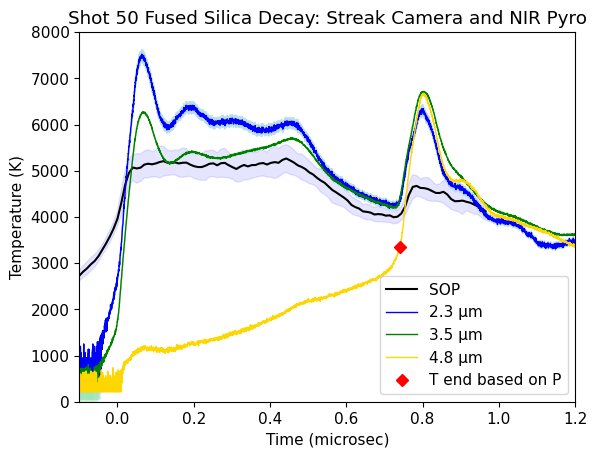

In [17]:
#plt.plot(s50time,s50temp,'+')
#plt.plot(s50time[ind50],s50temp[ind50],'+',label='SOP')
#plt.fill_between(s50time[ind50],s50temp[ind50]-s50temperr[ind50],s50temp[ind50]+s50temperr[ind50], color='blue', alpha = 0.1)
plt.plot(calstreak[:,0],calstreak[:,1],'k-',label='SOP')
plt.fill_between(calstreak[:,0],calstreak[:,1]-calstreak[:,2],calstreak[:,1]+calstreak[:,2], color='blue', alpha = 0.1)

#plt.plot(s50time,s50C2Tr,'+',label='2.3 um')
#plt.plot(C2.shot_t*1.e6,C2.Tr,label='2.3 um')
plt.plot(C2.shot_t*1.e6, C2.Tr, label='2.3 μm', linewidth=1,color='blue')
plt.fill_between(C2.shot_t*1.e6, C2.Tr-C2.Tr_er, C2.Tr+C2.Tr_er, alpha=0.8, color='lightblue')
plt.plot(C3.shot_t*1.e6, C3.Tr, label='3.5 μm', linewidth=1,color='green')
plt.fill_between(C3.shot_t*1.e6, C3.Tr-C3.Tr_er, C3.Tr+C3.Tr_er, alpha=0.4, color='lightgreen')
plt.plot(C4.shot_t*1.e6, C4.Tr, label='4.8 μm', linewidth=1,color='gold')

plt.plot([tend],[lasttemp],'rD',label='T end based on P')

plt.ylim(0,8000)
plt.xlim(-.1,1.2)
#plt.plot([.1,.1],[4000,6500])
#plt.plot([.2,.2],[4000,6500])
plt.xlabel('Time (microsec)')
plt.ylabel('Temperature (K)')
plt.title('Shot 50 Fused Silica Decay: Streak Camera and NIR Pyro')
plt.legend(loc='lower right')
plt.savefig('shot50/sop-nir-comp.pdf')
#plt.show()



The NIR temperatures are shown assuming emissivity = 1. Lower emissivities shift the temperatures higher.

Each wavelength has a different absorption coefficient. Need to model to determine front temperature vs. time.

The 4.8 micron channel is most absorbing and needs an emissivity correction. The end of that record might represent the just before breakout temperature. We had to estimate the final pressure. Using the model FS hugoniot, the red diamond is the expected temperature just before breakout.

The 2.3 micron channel is most transparent. The high temperature might mean there is an impact flash but none was obvious in the SOP. So that discrepancy is a mystery. Note that the calibration data for this shot had a large error bar on the 2.3 micron channel.

Overall, these data support the idea that the visible thermal emission during the shock decay is being contaminated by hotter fused silica behind the shock front.

Would be worth fitting the 4.8 micron channel with a Luo type model.

The agreement between all the NIR channels during the fiber strike is interesting. Suggests that the calibration is good and the differences are related to the target material.

The disagreement between the NIR and SOP at fiber strike is likely related to different fiber composition.


## Fit temperature vs time for absorbing 4.8 micron channel


5170.920498064298
59516762063.92477


/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_47594/374914033.py:51: RuntimeWarning: invalid value encountered in log
  Tbackout_down = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout_down*C4.wvln**5)+1))


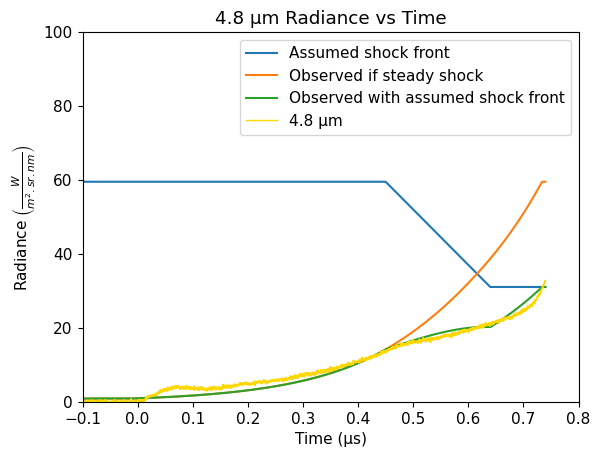

In [18]:
#Radiance vs time

Ltest = C4.c1/((C4.wvln**5)*(np.exp(C4.c2/(C4.wvln*C4.T))-1)) # W/m2/sr/m

Lsteady = C4.c1/((C4.wvln**5)*(np.exp(C4.c2/(C4.wvln*Tsteady))-1)) # W/m2/sr/m
print(Tsteady)
print(Lsteady)
s50dx = (max(xpos2)-xpos2)

if 0:
    plt.plot(s50time,xpos2/1.e3)
    plt.xlim(-0.1, .8)
    plt.xlabel('Time (μs)')
    plt.ylabel('Position (mm)')
    plt.show()
    
    plt.plot(s50time,s50dx/1.e3)
    plt.xlim(-0.1, .8)
    plt.xlabel('Time (μs)')
    plt.ylabel('Shock front depth (mm)')
    plt.show()

Lstart = Lsteady # W/m2/sr/m
abs_start = 8e-4# 1/m
#abs_start = 621.79e-6 # 1/m measured in lab fused silica
Dabs = np.interp(C4.shot_t*1.e6,s50time,s50dx)

Lprofile = np.zeros(len(C4.shot_t))
ind = np.where(C4.shot_t*1.e6 < tdecay)[0]
Lprofile[ind] = Lsteady
ind = np.where(C4.shot_t*1.e6 >= tdecay)[0]
Lprofile[ind] = Lsteady+(tdecay-C4.shot_t[ind]*1.e6)*15.e10
ind = np.where(C4.shot_t*1.e6 >= tkink)[0]
Lprofile[ind] = Lprofile[ind[0]-1]
#print(tdecay)
#plt.plot(C4.shot_t*1.e6,Lprofile)
#plt.xlim(-0.1, .8)
#plt.ylim(0,Lsteady*1.1)
#plt.show()

Lobs = Lstart*np.exp(-abs_start*Dabs)
Lobs2 = Lprofile*np.exp(-abs_start*Dabs)
Tprofile = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lprofile*C4.wvln**5)+1))
s50tempC4 = np.interp(s50time,C4.shot_t*1.e6,Tprofile)

Lbackout = C4.L/np.exp(-abs_start*Dabs)
Lbackout_up = (C4.L+C4.L_er)/np.exp(-abs_start*Dabs)
Lbackout_down = (C4.L-C4.L_er)/np.exp(-abs_start*Dabs)
Tbackout = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout*C4.wvln**5)+1))
Tbackout_up = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout_up*C4.wvln**5)+1))
Tbackout_down = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout_down*C4.wvln**5)+1))
s50tempbackout = np.interp(s50time,C4.shot_t*1.e6,Tbackout)
s50tempbackout_up = np.interp(s50time,C4.shot_t*1.e6,Tbackout_up)
s50tempbackout_down = np.interp(s50time,C4.shot_t*1.e6,Tbackout_down)

tind = np.where(C4.shot_t*1.e6<tend)[0]

#print(Lobs)

emis=1.
if 0:
    plt.plot(C4.shot_t[tind]*1.e6,emis*Lobs[tind]/1.e9,label='Observed if steady shock')
    plt.plot(C4.shot_t[tind]*1.e6,Lprofile[tind]/1.e9,label='Assumed shock front')
    plt.plot(C4.shot_t[tind]*1.e6,emis*Lobs2[tind]/1.e9,label='Observed shock front')
    plt.xlim(-0.1, .8)
    plt.ylim(0,Lsteady*1.1/1.e9)
    plt.xlabel('Time (μs)')
    plt.ylabel(r'Radiance $\left(\frac{W}{m^2.sr.nm} \right)$')
    plt.legend()
    plt.show()


plt.figure()
plt.plot(C4.shot_t[tind]*1.e6,Lprofile[tind]/1.e9,label='Assumed shock front')
plt.plot(C4.shot_t[tind]*1.e6, emis*Lobs[tind]/1.e9,label='Observed if steady shock')
plt.plot(C4.shot_t[tind]*1.e6, emis*Lobs2[tind]/1.e9,label='Observed with assumed shock front')
plt.plot(C4.shot_t[tind]*1.e6, C4.L[tind]/1.e9, label='4.8 μm', linewidth=1,color='gold')
plt.fill_between(C4.shot_t[tind]*1.e6, C4.L_plus[tind]/1.e9, C4.L_minus[tind]/1.e9, alpha=0.4, color='gold' )

plt.xlabel('Time (μs)')
plt.ylabel(r'Radiance $\left(\frac{W}{m^2.sr.nm} \right)$')
plt.title('4.8 μm Radiance vs Time')
plt.xlim(-0.1, .8)
plt.ylim(0,100)
plt.legend(loc='upper right')
plt.savefig('./shot50/shot50-4.8-model.pdf')
plt.show()






## Save Shot 50 Analysis

In [19]:
isort50=isort
# Saving the objects:
with open('shot50/shot50-analysis.pkl', 'wb') as f:  # Python 3: open(..., 'wb')
    pickle.dump([s50time, s50temp, s50temperr, s50pres, s50us, s50up, ind50, isort50,s50tempbackout,Tsteady,Tsteady_err,Psteady,usstart], f)
#with open(silicadatadir+'Amodeo-analysis/shot50-analysis.pkl', 'wb') as f:  # Python 3: open(..., 'wb')
#    pickle.dump([s50time, s50temp, s50temperr, s50pres, s50us, s50up, ind50, isort50,s50tempbackout,Tsteady,Tsteady_err,Psteady,usstart], f)


## Plot shots 50 and 60

In [20]:
# load shot 60


#with open(silicadatadir+'Amodeo-analysis/shot60-analysis.pkl', 'rb') as f: 
with open('shot60/shot60-analysis.pkl', 'rb') as f: 
    s60time, s60temp, s60temperr, s60pres, s60us, s60us_err, s60up, ind60, isort60,s60Tsteady,s60Tsteady_err,s60Psteady,s60Psteady_err,s60Ussteady,s60Ussteady_err=pickle.load(f)


0.4323366834170853 0.45


<Figure size 800x600 with 0 Axes>

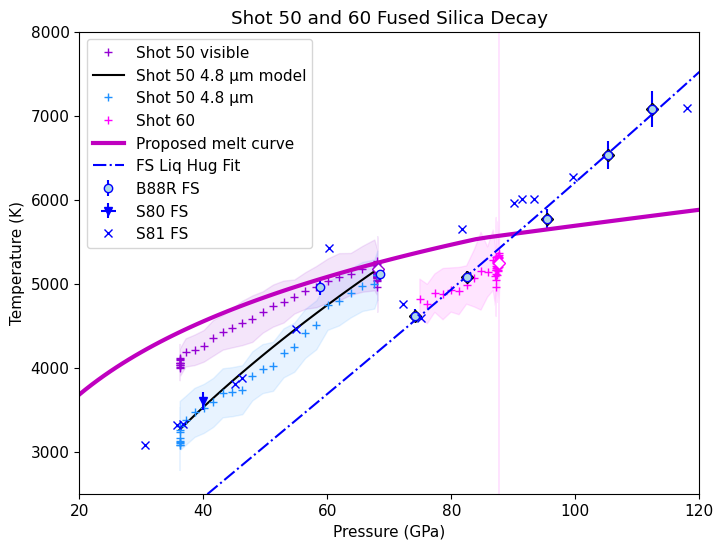

In [21]:
%run -i scripts/set_plotstyle

fig = plt.figure(figsize=fsize)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Shot 50 and 60 Fused Silica Decay')
plt.plot(s50pres[ind50],s50temp[ind50],'+',color='darkviolet',label='Shot 50 visible')
plt.plot(s50pres[ind50],s50tempC4[ind50],'-',color='k',label='Shot 50 4.8 μm model')
plt.plot(s50pres[ind50[40::]],s50tempbackout[ind50[40::]],'+',color='dodgerblue',label='Shot 50 4.8 μm')

#plt.fill_between(s50pres[ind50[40::]],s50tempbackout_down[ind50[40::]],s50tempbackout_up[ind50[40::]], color='blue', alpha = 0.1)
plt.fill_between(s50pres[ind50[40::]],s50tempbackout[ind50[40::]]-Tsteady_err,s50tempbackout[ind50[40::]]+Tsteady_err, color='dodgerblue', alpha = 0.1)

plt.fill_between(s50pres[ind50[isort]],s50temp[ind50[isort]]-s50temperr[ind50[isort]],s50temp[ind50[isort]]+s50temperr[ind50[isort]], color='darkviolet', alpha = 0.1)
print(s50time[ind50[40]],tdecay)
# plot the shot 50 IM solution point
#68.23569784953546 1.4210854715202004e-14
#5170.920498064298 19.364571422900298
plt.errorbar(68.2,5170,fmt='D',mfc='white',mec='darkviolet',yerr=19)#,label='Shot 50')
#
plt.plot(s60pres[ind60],s60temp[ind60],'+',color='magenta',label='Shot 60')
plt.fill_between(s60pres[ind60[isort60]],s60temp[ind60[isort60]]-s60temperr[ind60[isort60]],s60temp[ind60[isort60]]+s60temperr[ind60[isort60]], color='magenta', alpha = 0.1)
# plot the shot 60 IM solution point
plt.errorbar(87.7,5250,fmt='D',mec='magenta',mfc='white',xerr=.3,yerr=27)#,label='Shot 60')

if 1:
    #plt.errorbar(shockdat_list[B88fs['id']].P,shockdat_list[B88fs['id']].T,fmt='bo',mfc='white',yerr=shockdat_list[B88fs['id']].T_std,label=B88fs['lab'])
    ind = np.where(shockdat_list[B88RRfs['id']].T>0)
    plt.errorbar(shockdat_list[B88RRfs['id']].P[ind],shockdat_list[B88RRfs['id']].T[ind],fmt='bo',mfc='lightblue',yerr=shockdat_list[B88RRfs['id']].T_std[ind],label=B88RRfs['lab'])

    plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
    plt.errorbar(shockdat_list[S81fs['id']].P,shockdat_list[S81fs['id']].T,fmt='bx',label=S81fs['lab'])

    for i in range(len(fs_good_list)):
        plt.plot(fs_good_list[i].P,fs_good_list[i].T,'D',mfc='yellow',mec='k')
    plt.xlim(20,120)
    plt.ylim(2500,8000)
    plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Proposed melt curve')

#    plt.plot(fs_hug_liq.P,fs_hug_liq.T,'b-',label='FS Liq Hug')
    #plt.plot(fs_hug_RTK19.P,fs_hug_RTK19.T,'b-',label='FS Liq Hug Root')
    plt.plot(fs_hug_liq.P,fs_hug_liq.T,'b-.',label='FS Liq Hug Fit')


if 0:
    P3=90
    T3 = np.interp(P3,stsmcsmooth.P,stsmcsmooth.T)
    T2 = np.interp(fs_wiggle_P2,stsmcsmooth.P,stsmcsmooth.T)
    T1 = np.interp(fs_wiggle_P1,stsmcsmooth.P,stsmcsmooth.T)
    #S3 = np.interp(P3,stsmcsmooth.P,stsmcsmooth.S_l)
#    S2 = np.interp(fs_wiggle_P2,stsmcsmooth.P,stsmcsmooth.S_s)
#    S1 = np.interp(fs_wiggle_P1,stsmcsmooth.P,stsmcsmooth.S)
    plt.plot(fs_wiggle_P1,T1,'D')
    plt.plot(fs_wiggle_P2,T2,'D')
    plt.plot(P3,T3,'D')
#    print(fs_wiggle_P2,fs_wiggle_P1,P3,S2,S3)
#    print(T2,T3,5400*(S3-S2),(S3-S2))
    plt.plot(fs_hug_stv.P,fs_hug_stv.T,'b--')


plt.legend(loc='upper left')
plt.savefig('output-figs/shot50-60-comp-data.png')
plt.savefig('output-figs/shot50-60-comp-data.pdf')
plt.show()

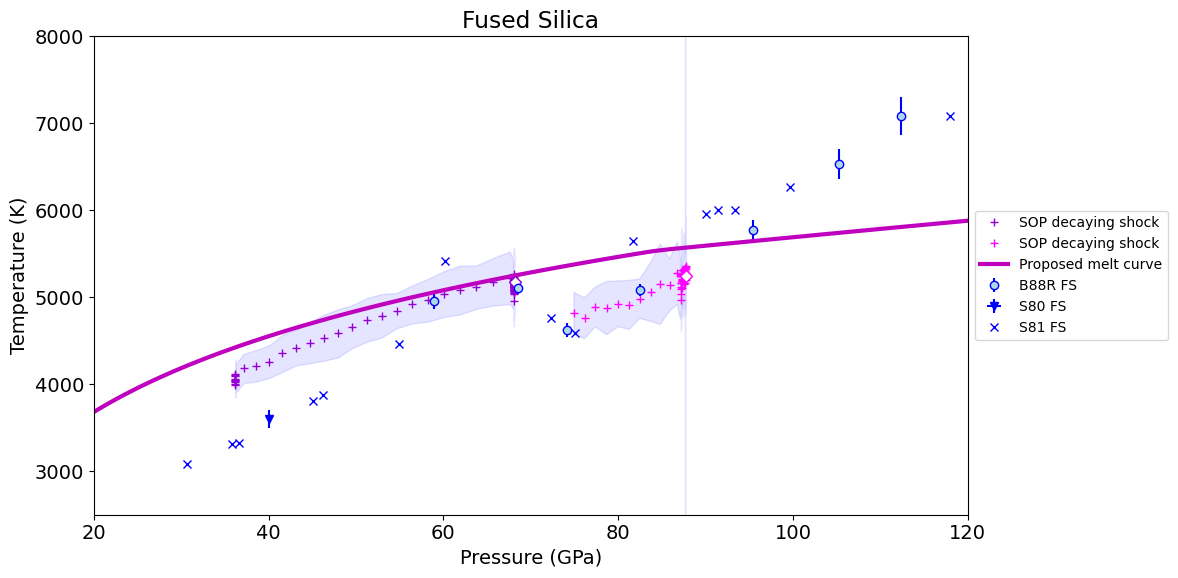

In [22]:

fig = plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.size': 14})

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Fused Silica')
plt.plot(s50pres[ind50],s50temp[ind50],'+',color='darkviolet',label='SOP decaying shock')
plt.fill_between(s50pres[ind50[isort50]],s50temp[ind50[isort50]]-s50temperr[ind50[isort50]],s50temp[ind50[isort50]]+s50temperr[ind50[isort50]], color='blue', alpha = 0.1)
# plot the shot 50 IM solution point
#68.23569784953546 1.4210854715202004e-14
#5170.920498064298 19.364571422900298
plt.errorbar(68.2,5170,fmt='D',mfc='white',mec='darkviolet',yerr=19)#,label='Vis decaying shock')
#
plt.plot(s60pres[ind60],s60temp[ind60],'+',color='magenta',label='SOP decaying shock')
plt.fill_between(s60pres[ind60[isort60]],s60temp[ind60[isort60]]-s60temperr[ind60[isort60]],s60temp[ind60[isort60]]+s60temperr[ind60[isort60]], color='blue', alpha = 0.1)
# plot the shot 60 IM solution point
plt.errorbar(87.7,5250,fmt='D',mec='magenta',mfc='white',xerr=.3,yerr=27)#,label='Vis decaying shock')

if 1:
    #plt.errorbar(shockdat_list[B88fs['id']].P,shockdat_list[B88fs['id']].T,fmt='bo',mfc='white',yerr=shockdat_list[B88fs['id']].T_std,label=B88fs['lab'])
    ind = np.where(shockdat_list[B88RRfs['id']].T>0)
    plt.errorbar(shockdat_list[B88RRfs['id']].P[ind],shockdat_list[B88RRfs['id']].T[ind],fmt='bo',mfc='lightblue',yerr=shockdat_list[B88RRfs['id']].T_std[ind],label=B88RRfs['lab'])

    plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
    plt.errorbar(shockdat_list[S81fs['id']].P,shockdat_list[S81fs['id']].T,fmt='bx',label=S81fs['lab'])
    plt.xlim(20,120)
    plt.ylim(2500,8000)
    plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Proposed melt curve')

#plt.legend()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)

plt.tight_layout()
plt.savefig(outputfigpath+'shot50-60-comp-data.png')
plt.savefig(outputfigpath+'shot50-60-comp-data.pdf')
plt.show()

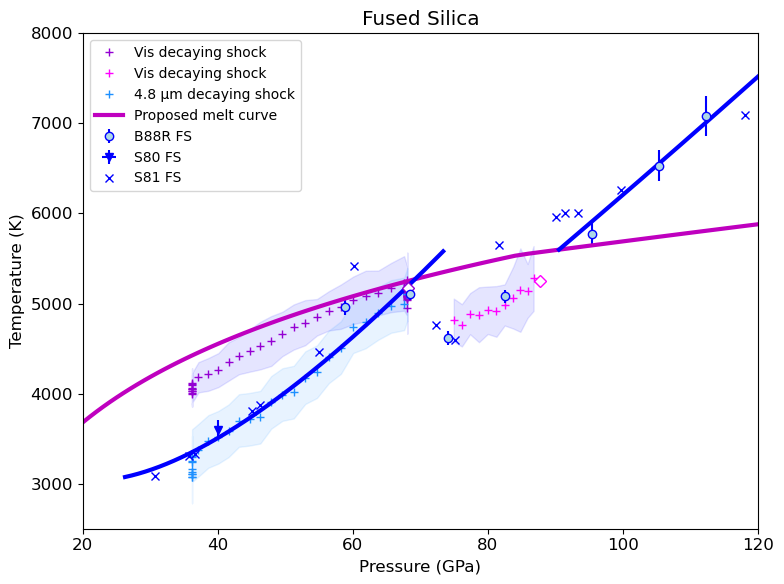

In [23]:
#fig = plt.figure(figsize=(12, 6))
#plt.rcParams.update({'font.size': 14})
#fig = plt.figure(figsize=(10, 8))
#plt.rcParams.update({'font.size': 24})
plt.rcParams.update(plt.rcParamsDefault)
fsize=(8, 6) # default figure size in inches
plt.figure(figsize=fsize) 
fss=12 # figure font size
plt.rcParams.update({'font.size': fss})
lfss = 10 # legend font size
tss=12

isort60p = np.arange(47,58,1)

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('Fused Silica')
plt.plot(s50pres[ind50],s50temp[ind50],'+',color='darkviolet',label='Vis decaying shock')
plt.fill_between(s50pres[ind50[isort50]],s50temp[ind50[isort50]]-s50temperr[ind50[isort50]],s50temp[ind50[isort50]]+s50temperr[ind50[isort50]], color='blue', alpha = 0.1)
# plot the shot 50 IM solution point
#68.23569784953546 1.4210854715202004e-14
#5170.920498064298 19.364571422900298
plt.errorbar(68.2,5170,fmt='D',mfc='white',mec='darkviolet',yerr=19)#,label='Vis decaying shock')
#
plt.plot(s60pres[ind60[isort60p]],s60temp[ind60[isort60p]],'+',color='magenta',label='Vis decaying shock')
plt.fill_between(s60pres[ind60[isort60p]],s60temp[ind60[isort60p]]-s60temperr[ind60[isort60p]],s60temp[ind60[isort60p]]+s60temperr[ind60[isort60p]], color='blue', alpha = 0.1)
# plot the shot 60 IM solution point
plt.errorbar(87.7,5250,fmt='D',mec='magenta',mfc='white',xerr=.3,yerr=27)#,label='Vis decaying shock')
plt.plot(s50pres[ind50[40::]],s50tempbackout[ind50[40::]],'+',color='dodgerblue',label='4.8 μm decaying shock')
plt.fill_between(s50pres[ind50[40::]],s50tempbackout[ind50[40::]]-Tsteady_err,s50tempbackout[ind50[40::]]+Tsteady_err, color='dodgerblue', alpha = 0.1)

if 1:
    #plt.errorbar(shockdat_list[B88fs['id']].P,shockdat_list[B88fs['id']].T,fmt='bo',mfc='white',yerr=shockdat_list[B88fs['id']].T_std,label=B88fs['lab'])
    ind = np.where(shockdat_list[B88RRfs['id']].T>0)
    plt.errorbar(shockdat_list[B88RRfs['id']].P[ind],shockdat_list[B88RRfs['id']].T[ind],fmt='bo',mfc='lightblue',yerr=shockdat_list[B88RRfs['id']].T_std[ind],label=B88RRfs['lab'])

    plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
    plt.errorbar(shockdat_list[S81fs['id']].P,shockdat_list[S81fs['id']].T,fmt='bx',label=S81fs['lab'])
    plt.xlim(20,120)
    plt.ylim(2500,8000)
    plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Proposed melt curve')
ind=np.where(fs_hug_liq.P>fs_startliq_P)[0]
plt.plot(fs_hug_liq.P[ind],fs_hug_liq.T[ind],'b-',linewidth=3)
ind=np.where(fs_hug_stv.P<fs_wiggle_P2)[0]
plt.plot(fs_hug_stv.P[ind],fs_hug_stv.T[ind],'b-',linewidth=3)
plt.legend(fontsize=lfss)
#plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)

plt.tight_layout()
plt.savefig(outputfigpath+'shot50-60-comp-data2.png')
plt.savefig(outputfigpath+'shot50-60-comp-data2.pdf')
plt.show()

<Figure size 800x600 with 0 Axes>

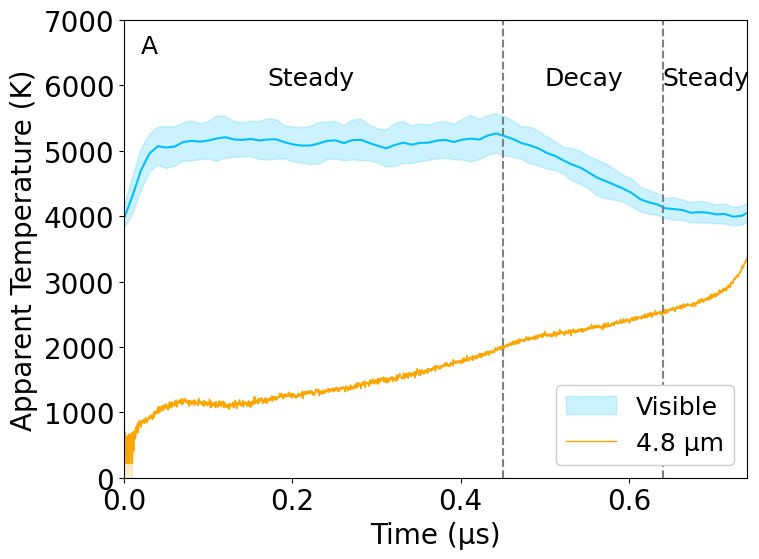

In [38]:

%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
plt.rcParams.update({'font.size': 20})

plt.figure(figsize=fsize)
plt.plot(calstreak[:,0],calstreak[:,1],'-',color='deepskyblue')
plt.fill_between(calstreak[:,0],calstreak[:,1]-calstreak[:,2],calstreak[:,1]+calstreak[:,2], color='deepskyblue', alpha = 0.2,label='Visible')

#plt.plot(s50time,s50C2Tr,'+',label='2.3 um')
#plt.plot(C2.shot_t*1.e6,C2.Tr,label='2.3 um')
#plt.plot(C2.shot_t*1.e6, C2.Tr, label='2.3 μm', linewidth=1,color='blue')
#plt.fill_between(C2.shot_t*1.e6, C2.Tr-C2.Tr_er, C2.Tr+C2.Tr_er, alpha=0.8, color='lightblue')
#plt.plot(C3.shot_t*1.e6, C3.Tr, label='3.5 μm', linewidth=1,color='green')
#plt.fill_between(C3.shot_t*1.e6, C3.Tr-C3.Tr_er, C3.Tr+C3.Tr_er, alpha=0.4, color='lightgreen')
plt.plot(C4.shot_t*1.e6, C4.Tr, label='4.8 μm', linewidth=1,color='orange')
plt.fill_between(C4.shot_t*1.e6, C4.Tr-C4.Tr_er, C4.Tr+C4.Tr_er, alpha=0.2, color='orange')

#print(C4.Tr_er)
#plt.plot([tend],[lasttemp],'rD',label='T end based on P')

plt.ylim(0,7000)
plt.xlim(0,tend)
plt.xlabel('Time (μs)')
plt.ylabel('Apparent Temperature (K)')

tfss=18
plt.plot([tdecay,tdecay],[0,7000],'--',color='grey')
plt.plot([tkink,tkink],[0,7000],'--',color='grey')
plt.text(0.17,6000,'Steady',fontsize=tfss)
plt.text(0.5,6000,'Decay',fontsize=tfss)
plt.text(0.64,6000,'Steady',fontsize=tfss)

plt.text(0.02,6500,'A',fontsize=tfss)


#plt.title('Shot 50 Fused Silica Decay: Streak Camera and NIR Pyro')
plt.legend(loc='lower right',framealpha=1,fontsize=18)
plt.tight_layout()#pad=0.4,w_pad=0.5,h_pad=1.0)


plt.savefig(outputfigpath+'shot50-sop-48-comp.pdf')
plt.savefig(figurefigpath+'shot50-sop-48-comp.pdf')
plt.show()



5170.920498064298
59516762063.92477


/var/folders/4z/xws_ywgj78sc494vpwymn9bw0000gn/T/ipykernel_47594/3196182585.py:53: RuntimeWarning: invalid value encountered in log
  Tbackout_down = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout_down*C4.wvln**5)+1))


<Figure size 800x600 with 0 Axes>

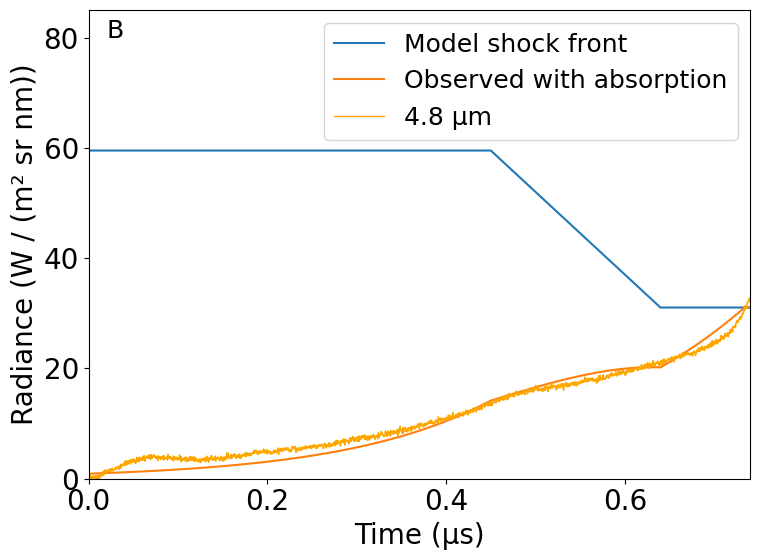

In [39]:
#Radiance vs time
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors
plt.rcParams.update({'font.size': 20})
Ltest = C4.c1/((C4.wvln**5)*(np.exp(C4.c2/(C4.wvln*C4.T))-1)) # W/m2/sr/m

Lsteady = C4.c1/((C4.wvln**5)*(np.exp(C4.c2/(C4.wvln*Tsteady))-1)) # W/m2/sr/m
print(Tsteady)
print(Lsteady)
s50dx = (max(xpos2)-xpos2)

if 0:
    plt.plot(s50time,xpos2/1.e3)
    plt.xlim(-0.1, .8)
    plt.xlabel('Time (μs)')
    plt.ylabel('Position (mm)')
    plt.show()
    
    plt.plot(s50time,s50dx/1.e3)
    plt.xlim(-0.1, .8)
    plt.xlabel('Time (μs)')
    plt.ylabel('Shock front depth (mm)')
    plt.show()

Lstart = Lsteady # W/m2/sr/m
abs_start = 8e-4# 1/m
#abs_start = 621.79e-6 # 1/m measured in lab fused silica
Dabs = np.interp(C4.shot_t*1.e6,s50time,s50dx)

Lprofile = np.zeros(len(C4.shot_t))
ind = np.where(C4.shot_t*1.e6 < tdecay)[0]
Lprofile[ind] = Lsteady
ind = np.where(C4.shot_t*1.e6 >= tdecay)[0]
Lprofile[ind] = Lsteady+(tdecay-C4.shot_t[ind]*1.e6)*15.e10
ind = np.where(C4.shot_t*1.e6 >= tkink)[0]
Lprofile[ind] = Lprofile[ind[0]-1]
#print(tdecay)
#plt.plot(C4.shot_t*1.e6,Lprofile)
#plt.xlim(-0.1, .8)
#plt.ylim(0,Lsteady*1.1)
#plt.show()

Lobs = Lstart*np.exp(-abs_start*Dabs)
Lobs2 = Lprofile*np.exp(-abs_start*Dabs)
Tprofile = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lprofile*C4.wvln**5)+1))
s50tempC4 = np.interp(s50time,C4.shot_t*1.e6,Tprofile)

Lbackout = C4.L/np.exp(-abs_start*Dabs)
Lbackout_up = (C4.L+C4.L_er)/np.exp(-abs_start*Dabs)
Lbackout_down = (C4.L-C4.L_er)/np.exp(-abs_start*Dabs)
Tbackout = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout*C4.wvln**5)+1))
Tbackout_up = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout_up*C4.wvln**5)+1))
Tbackout_down = ((1.4388*1.e-2)/C4.wvln)*(1/np.log((1.19118*1.e-16)/(Lbackout_down*C4.wvln**5)+1))
s50tempbackout = np.interp(s50time,C4.shot_t*1.e6,Tbackout)
s50tempbackout_up = np.interp(s50time,C4.shot_t*1.e6,Tbackout_up)
s50tempbackout_down = np.interp(s50time,C4.shot_t*1.e6,Tbackout_down)

tind = np.where(C4.shot_t*1.e6<tend)[0]

#print(Lobs)

emis=1.
if 0:
    plt.plot(C4.shot_t[tind]*1.e6,emis*Lobs[tind]/1.e9,label='Observed if steady shock')
    plt.plot(C4.shot_t[tind]*1.e6,Lprofile[tind]/1.e9,label='Assumed shock front')
    plt.plot(C4.shot_t[tind]*1.e6,emis*Lobs2[tind]/1.e9,label='Observed shock front')
    plt.xlim(-0.1, .8)
    plt.ylim(0,Lsteady*1.1/1.e9)
    plt.xlabel('Time (μs)')
    plt.ylabel(r'Radiance $\left(\frac{W}{m^2.sr.nm} \right)$')
    plt.legend()
    plt.show()

#fig, ax = plt.subplots(3,1,figsize=fsize3)
plt.figure(figsize=fsize)
plt.plot(C4.shot_t[tind]*1.e6,Lprofile[tind]/1.e9,label='Model shock front')
#plt.plot(C4.shot_t[tind]*1.e6, emis*Lobs[tind]/1.e9,label='Observed if steady shock')
plt.plot(C4.shot_t[tind]*1.e6, emis*Lobs2[tind]/1.e9,label='Observed with absorption')
plt.plot(C4.shot_t[tind]*1.e6, C4.L[tind]/1.e9, label='4.8 μm', linewidth=1,color='orange')
plt.fill_between(C4.shot_t[tind]*1.e6, C4.L_plus[tind]/1.e9, C4.L_minus[tind]/1.e9, alpha=0.4, color='gold' )

plt.text(0.02,80,'B',fontsize=18)
plt.xlabel('Time (μs)')
plt.ylabel('Radiance (W / (m² sr nm))')
#plt.title('4.8 μm Radiance vs Time')
plt.xlim(0,tend)
plt.ylim(0,85)
plt.legend(fontsize=18,loc='upper right')
plt.tight_layout()
plt.savefig('./shot50/shot50-4.8-model.pdf')
plt.savefig(figurefigpath+'shot50-4.8-model.pdf')
plt.show()




